In [1]:
from ObjaverseDataset import ObjaverseDataset
from torch.utils.data import DataLoader
from pathlib import Path
from utils import *

[transformers] Disabling PyTorch because PyTorch >= 2.4 is required but found 2.2.2
[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [2]:
objaverse_dataset = ObjaverseDataset(category="duck", limit=3)
objaverse_dataloader = DataLoader(objaverse_dataset, batch_size=1, shuffle=False, collate_fn=objaverse_dataset.collate_fn)

dict_keys(['Band_Aid', 'Bible', 'CD_player', 'Christmas_tree', 'Dixie_cup', 'Ferris_wheel', 'Lego', 'Rollerblade', 'Sharpie', 'Tabasco_sauce', 'aerosol_can', 'air_conditioner', 'airplane', 'alarm_clock', 'alcohol', 'alligator', 'almond', 'ambulance', 'amplifier', 'anklet', 'antenna', 'apple', 'apricot', 'apron', 'aquarium', 'arctic_(type_of_shoe)', 'armband', 'armchair', 'armoire', 'armor', 'army_tank', 'artichoke', 'ashtray', 'asparagus', 'atomizer', 'automatic_washer', 'avocado', 'award', 'awning', 'ax', 'baboon', 'baby_buggy', 'backpack', 'bagel', 'baguet', 'bait', 'ball', 'ballet_skirt', 'balloon', 'bamboo', 'banana', 'bandage', 'bandanna', 'banjo', 'banner', 'barbell', 'barge', 'barrel', 'barrow', 'baseball', 'baseball_bat', 'baseball_cap', 'baseball_glove', 'basket', 'basketball', 'basketball_backboard', 'bass_horn', 'bat_(animal)', 'bath_mat', 'bath_towel', 'bathrobe', 'bathtub', 'battery', 'beachball', 'bead', 'beanbag', 'beanie', 'bear', 'bed', 'bedpan', 'bedspread', 'beef_(fo

['b5c9d06f19be4c92a1708515f6655573']
FEngine (64 bits) created at 0x32c07e200 (threading is enabled)
FEngine resolved backend: Metal
Selected physical device 'Apple M4'
Supported GPU families: 
  MTLGPUFamilyCommon3
  MTLGPUFamilyApple7
  MTLGPUFamilyMac2
Features:
  readWriteTextureSupport: true
Backend feature level: 3
FEngine feature level: 1


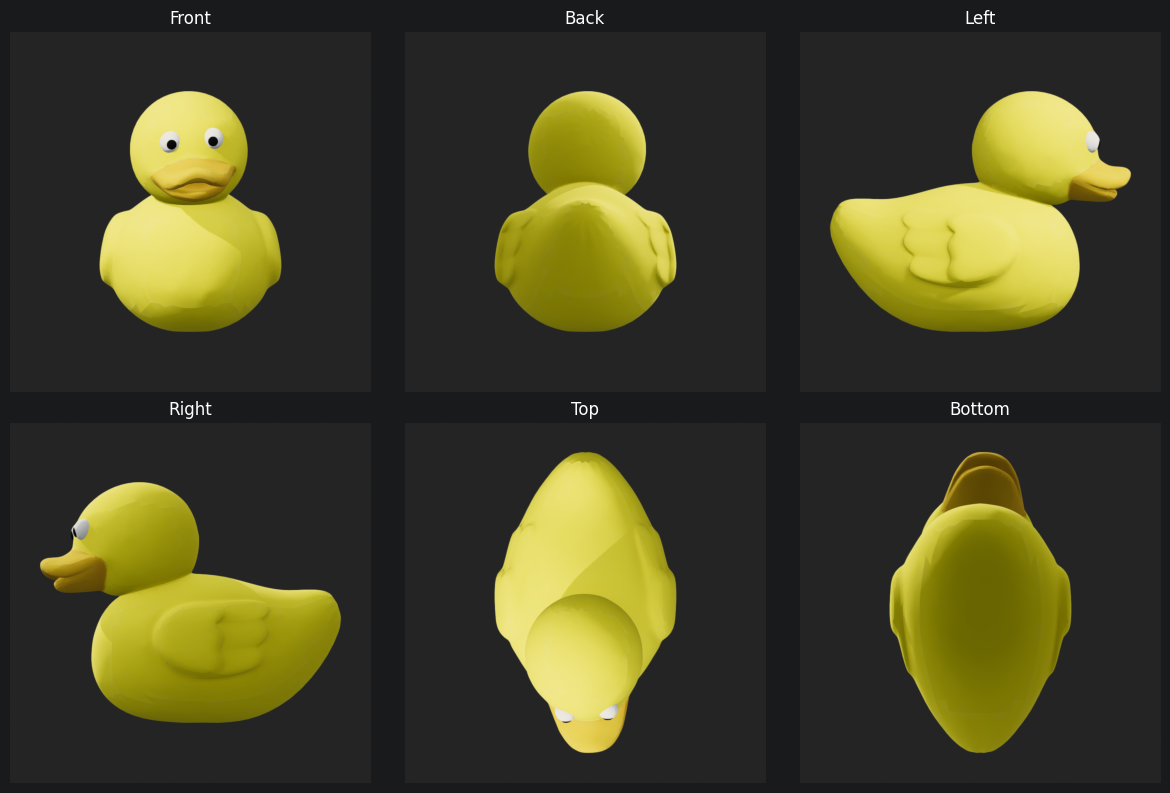

Do not add mask to the set
Image size (H, W, C): (1008, 1008, 3)


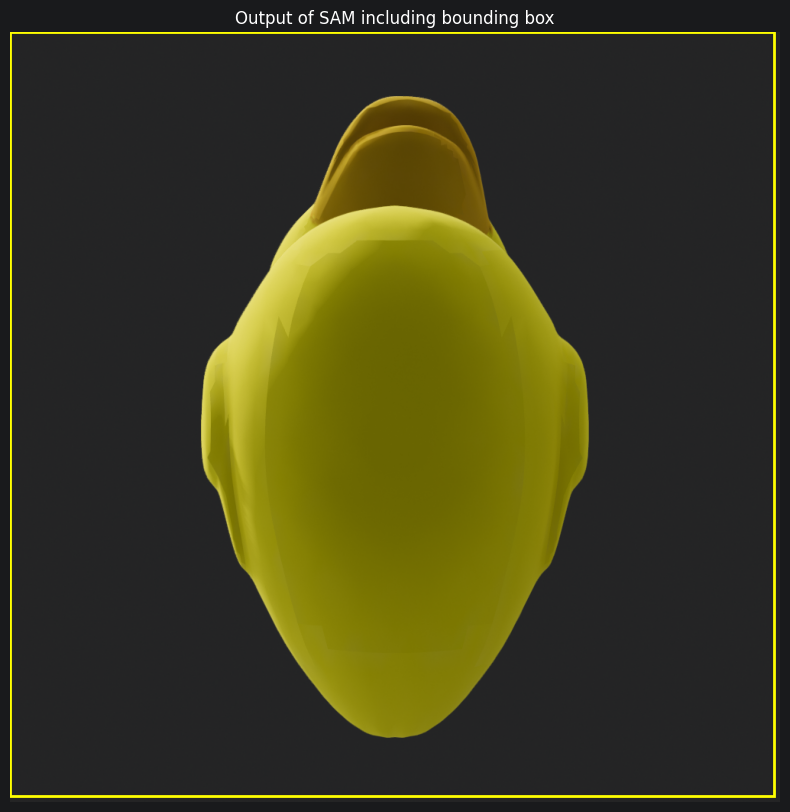

{
  "bbox_2d": [750, 370, 925, 500],
  "is_found": true
}
./weights are already installed
Image size (H, W, C): (1008, 1008, 3)


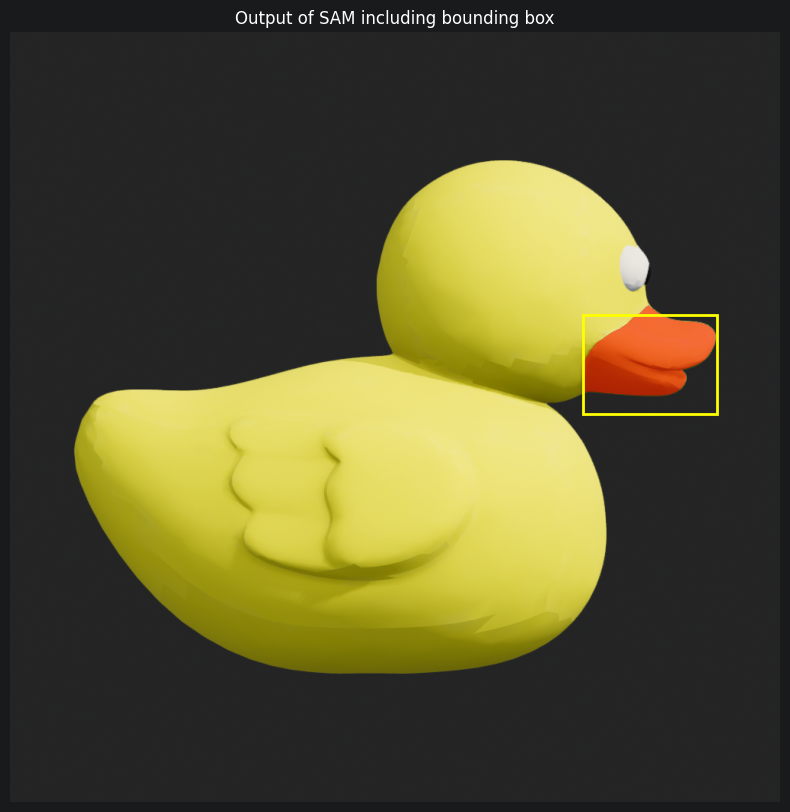

added mask to the set
{
  "bbox_2d": [400, 350, 500, 600],
  "is_found": true
}
./weights are already installed


KeyboardInterrupt: 

In [3]:
# Test case 1: detect and remove beak for 3 duck objects

# load every 3d object
for batch in objaverse_dataloader:
    print(batch["uid"])
    mesh = batch["mesh"][0]
    # 1. Render the object from 6 views
    render_6_views(mesh, f"rendered_views/{batch['uid']}")
    show_rendered_grid(f"rendered_views/{batch['uid']}")

    # 2. Decide which feature should be detected
    feature_to_detect = "beak"
    valid_masks_set = []
    # 3. For every view detect the decided feature and generate bounding box
    for view_path in Path(f"rendered_views/{batch['uid']}").iterdir():
        json_output = generate_bounding_box_for_image("192.168.178.23", view_path, f"{feature_to_detect}")
        data = json.loads(json_output)
        is_found = data['is_found']
        if not is_found:
            print("Do not add mask to the set")
            visualize_segmentation(image_path=view_path ,mask=None,x1= 0,y1= 0,x2= 1000,y2= 1000)
            continue
        four_coordinates = data['bbox_2d']
        x1= four_coordinates[0]
        y1= four_coordinates[1]
        x2= four_coordinates[2]
        y2= four_coordinates[3]
        print(json_output)
        mask = segment_image(view_path, x1, y1, x2, y2)
        visualize_segmentation(image_path=view_path ,mask=mask,x1= x1,y1= y1,x2= x2,y2= y2)
        valid_masks_set.append(mask)
        print("added mask to the set")

        # generate_bounding_box_for_image("192.168.178.23", image_path=f"rendered_views/{batch['uid']}/{view_path}")
    # x1=250
    # y1=100
    # x2=550
    # y2=400
    # mask = segment_image(f"rendered_views/{batch['uid']}/front.png", x1, y1, x2, y2)
    # visualize_segmentation(image_path= f"rendered_views/{batch['uid']}/front.png",mask= mask,x1= x1,y1= y1,x2= x2,y2= y2)
